# 01 - Preprocessing (Week 2)

**Goal:** build the preprocessing every model will use, and check it visually and for speed.

Why each step (based on Week 1 findings):
- **Greyscale, then 3 identical channels:** MRI is grey; Week 1 showed the stored colour mode (L vs RGB) is linked to the class, so we remove it. Pretrained models expect 3 channels, so the grey channel is copied 3 times.
- **Crop the black border:** borders differ between image sources; cropping makes the brain fill the image.
- **Pad to square, then resize to 224x224:** sizes range from 150 to 1,920 px; padding keeps the brain's real shape (no stretching).
- **Cache:** the fixed steps above are done **once** and saved as small PNGs in `outputs/cache/`, so training does not repeat them every epoch.
- **Augmentation (train only):** flip, rotation +-10 deg, small brightness/contrast jitter, then ImageNet normalisation.

All code is in `src/data.py` (needed on Windows so DataLoader workers can import it). `./data/` is only read.

In [1]:
# Setup: work from the project root so 'data/' and 'outputs/' resolve.
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import pandas as pd
import torch
from IPython.display import Image as ShowImage, display
from src import data as d

d.set_seed(d.SEED)
torch.manual_seed(d.SEED)
SPLIT_DIR = Path('outputs/splits')
CACHE_DIR = Path('outputs/cache')
PLOT_DIR = Path('outputs/plots/week2')
PLOT_DIR.mkdir(parents=True, exist_ok=True)

D:\Brain-Tumor\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. CSV index files (columns: path, label, split)
One CSV per version with the **original** Training/Testing split (`train`/`test`). Validation and leakage-free splits come later.

In [2]:
files = d.list_images('data')
for v in ['v1', 'v2']:
    index = d.make_index_csv(files, v, SPLIT_DIR / f'{v}_original.csv')
    print(f'{v}: {len(index):,} rows ->', index['split'].value_counts().to_dict())
index.head()

v1: 7,023 rows -> {'train': 5712, 'test': 1311}
v2: 7,200 rows -> {'train': 5600, 'test': 1600}


,path,label,split
0,data\v2\Training\glioma\Tr-gl_1.jpg,glioma,train
1,data\v2\Training\glioma\Tr-gl_10.jpg,glioma,train
2,data\v2\Training\glioma\Tr-gl_100.jpg,glioma,train
3,data\v2\Training\glioma\Tr-gl_1000.jpg,glioma,train
4,data\v2\Training\glioma\Tr-gl_1001.jpg,glioma,train


## 2. Crop: before and after
Steps: blur -> Otsu threshold (automatic dark/bright cut) -> remove specks -> largest blob -> its box + 2% margin. If no sensible blob is found (or it covers <10% of the image) the full image is kept (*fallback*).

D:\Brain-Tumor\src\data.py:396: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


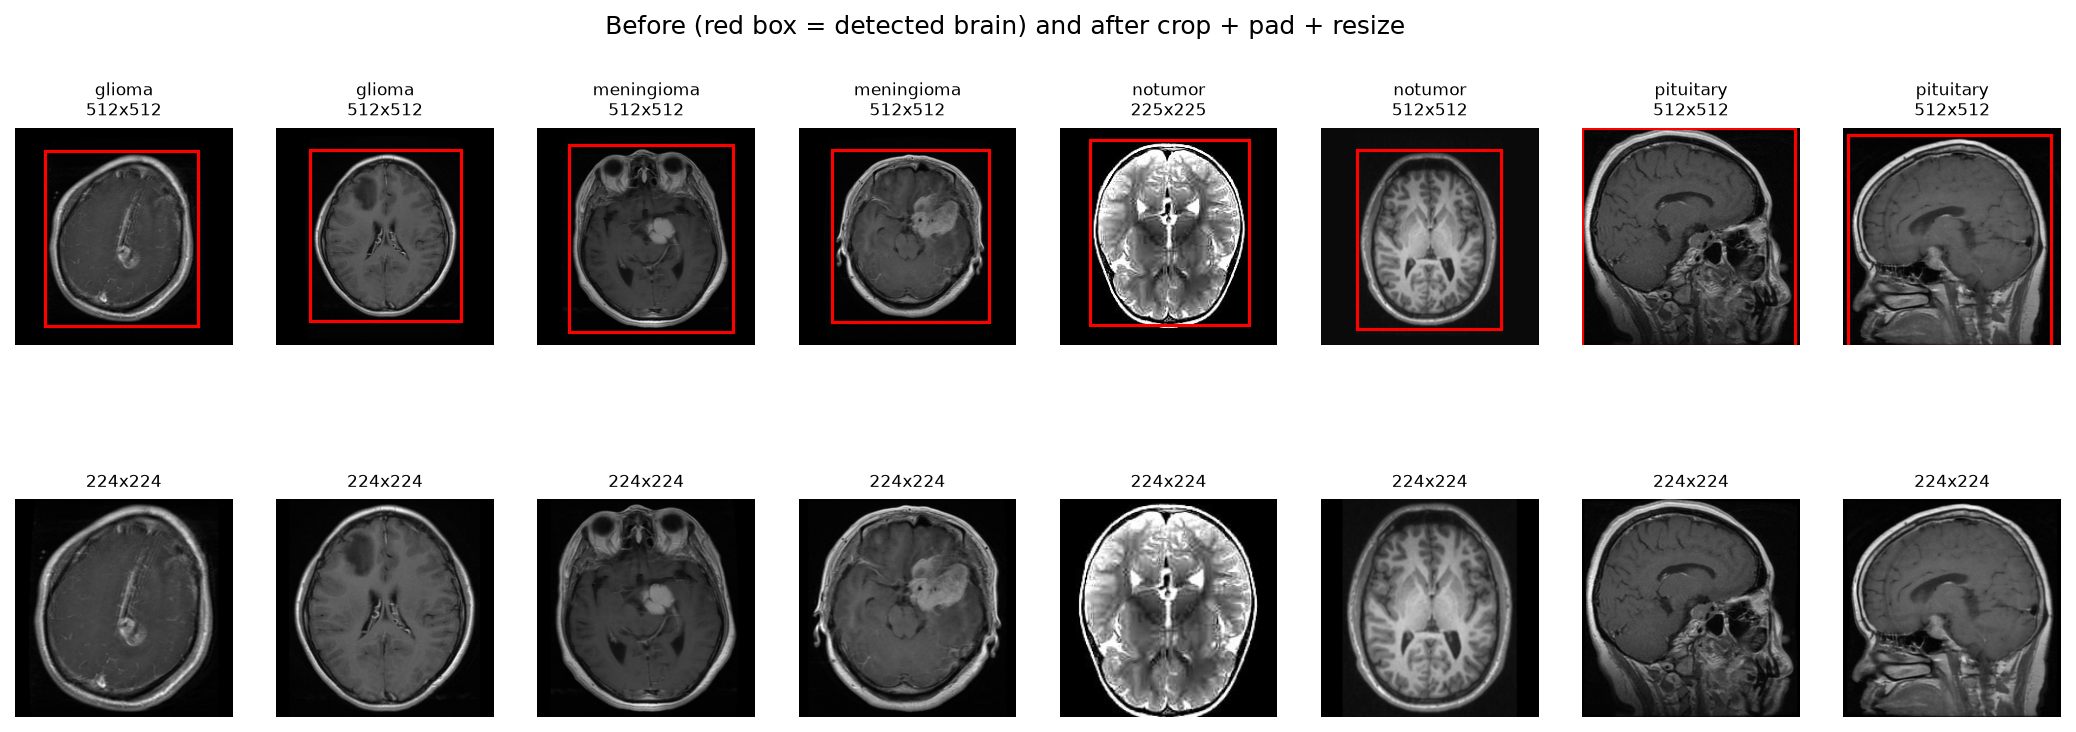

In [3]:
display(ShowImage(filename=str(d.plot_crop_examples(SPLIT_DIR / 'v1_original.csv', PLOT_DIR))))

## 3. Build the cache (done once; re-running skips finished files)

In [4]:
cache = {}
for v in ['v1', 'v2']:
    cache[v] = d.build_cache(SPLIT_DIR / f'{v}_original.csv', CACHE_DIR / f'{v}_224',
                             SPLIT_DIR / f'{v}_cache224.csv')
summary = []
for v, table in cache.items():
    size_mb = sum(Path(p).stat().st_size for p in table['path']) / 1e6
    summary.append({'version': v, 'cached_files': len(table),
                    'files_on_disk': sum(1 for _ in (CACHE_DIR / f'{v}_224').rglob('*.png')),
                    'size_MB': round(size_mb, 1),
                    'crop_fallbacks': int(table['crop_fallback'].sum()),
                    'fallback_%': round(100 * table['crop_fallback'].mean(), 2)})
pd.DataFrame(summary)

Caching v1_224:   0%|          | 0/7023 [00:00<?, ?it/s]

Caching v1_224:   0%|          | 14/7023 [00:00<00:55, 125.49it/s]

Caching v1_224:   0%|          | 31/7023 [00:00<00:51, 136.62it/s]

Caching v1_224:   1%|          | 47/7023 [00:00<00:48, 143.38it/s]

Caching v1_224:   1%|          | 64/7023 [00:00<00:47, 147.07it/s]

...

Caching v2_224: 100%|█████████▉| 7166/7200 [01:20<00:00, 133.47it/s]

Caching v2_224: 100%|█████████▉| 7180/7200 [01:20<00:00, 68.82it/s] 

Caching v2_224: 100%|█████████▉| 7191/7200 [01:20<00:00, 72.59it/s]

Caching v2_224: 100%|██████████| 7200/7200 [01:20<00:00, 89.27it/s]

,version,cached_files,files_on_disk,size_MB,crop_fallbacks,fallback_%
0,v1,7023,7023,181.1,10,0.14
1,v2,7200,7200,185.7,14,0.19


In [5]:
# Which classes needed the fallback (no crop)?
pd.concat(cache, names=['version']).groupby(['version', 'label'])['crop_fallback'].sum().unstack()

label,glioma,meningioma,notumor,pituitary
version,,,,
v1,0,2,7,1
v2,3,2,6,3


## 4. Augmentation examples
Per class: the cached image, the **eval** transform (resize + normalise only) and 5 random **train** augmentations (shown after undoing the normalisation).

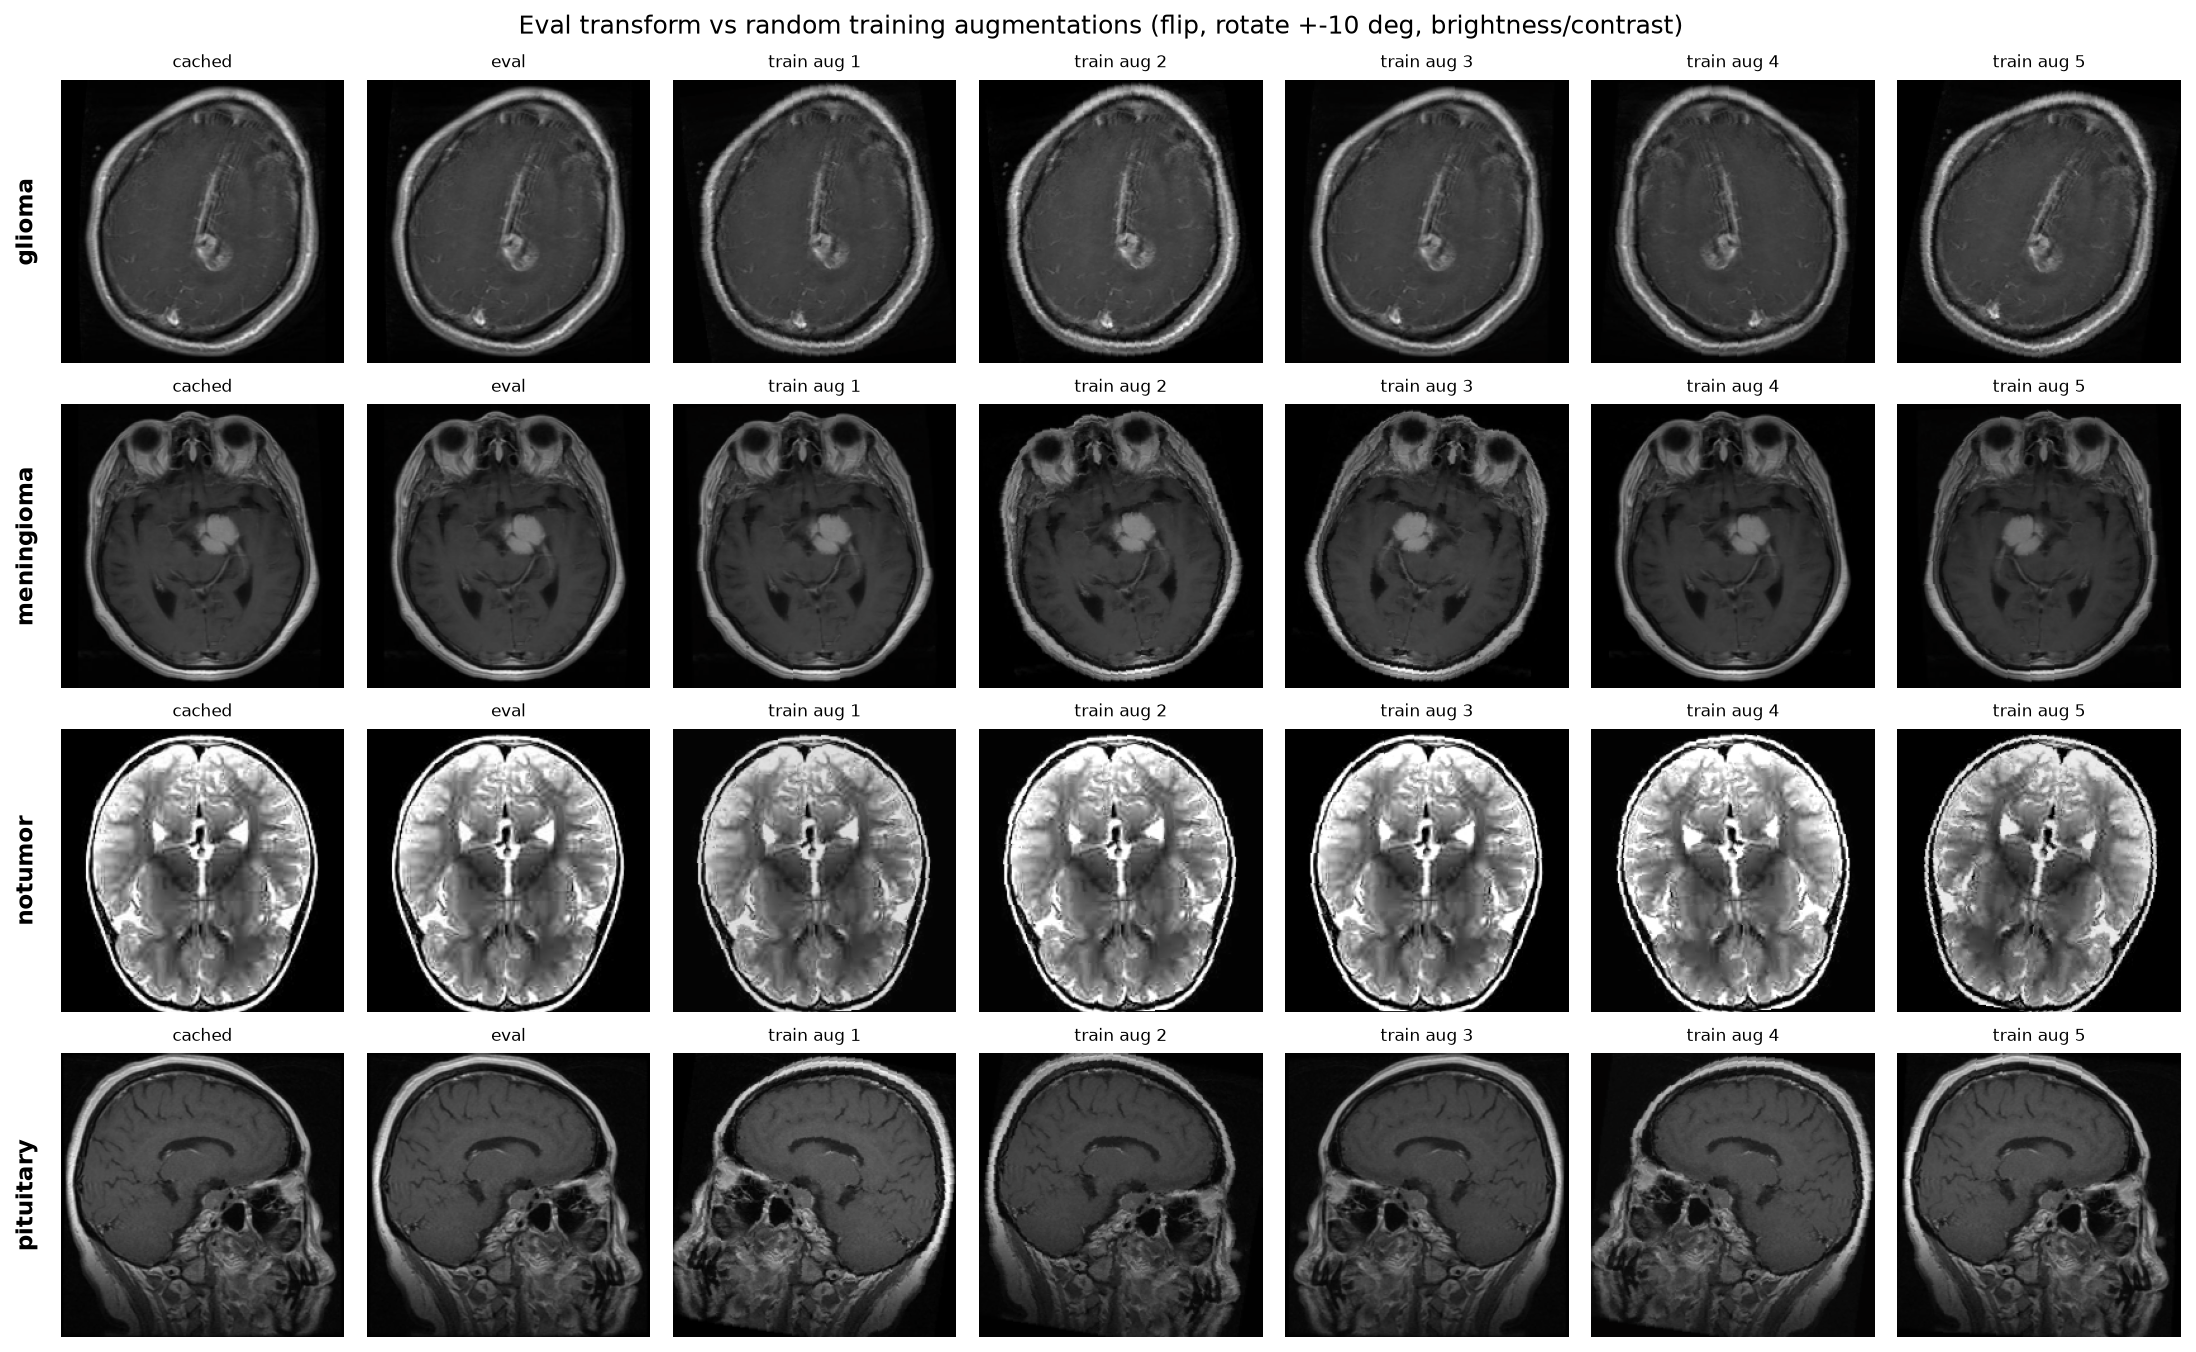

In [6]:
display(ShowImage(filename=str(d.plot_augment_examples(SPLIT_DIR / 'v1_cache224.csv', PLOT_DIR))))

## 5. The Dataset class
`MRIDataset(csv_path, split, transform, crop)` reads the CSV and returns `(image tensor, label index)`.

In [7]:
train_ds = d.MRIDataset(SPLIT_DIR / 'v1_cache224.csv', 'train', d.train_transforms())
test_ds = d.MRIDataset(SPLIT_DIR / 'v1_cache224.csv', 'test', d.eval_transforms())
x, y = train_ds[0]
print('train / test images:', len(train_ds), '/', len(test_ds))
print('one item:', tuple(x.shape), x.dtype, '| label', y, '=', d.CLASSES[y])
print(f'pixel mean {x.mean():.3f}, std {x.std():.3f}, min {x.min():.3f}, max {x.max():.3f}')
print('3 channels identical:', bool(torch.allclose(x[0] * d.IMAGENET_STD[0] + d.IMAGENET_MEAN[0],
                                                   x[1] * d.IMAGENET_STD[1] + d.IMAGENET_MEAN[1], atol=1e-5)))

train / test images: 5712 / 1311
one item: (3, 224, 224) torch.float32 | label 0 = glioma
pixel mean -1.379, std 0.693, min -2.118, max 2.431
3 channels identical: True


## 6. DataLoader speed: num_workers 0 vs 2
500 training images, batch 32, train augmentations. Two data sources:
- **raw**: original JPG, crop + resize done inside the Dataset every time;
- **cached**: the preprocessed 224 PNGs.

*Pass 1* includes starting the worker processes (slow on Windows); *pass 2* re-uses them (`persistent_workers=True`), which is what every later epoch looks like. We choose on pass 2 of the cached source.

In [8]:
raw_ds = d.MRIDataset(SPLIT_DIR / 'v1_original.csv', 'train', d.train_transforms(), crop=True)
rows = []
for source, ds in [('raw', raw_ds), ('cached', train_ds)]:
    for workers in [0, 2]:
        rows.append({'source': source, **d.time_loader(ds, workers, n_images=500)})
timing = pd.DataFrame(rows)
timing.to_csv(PLOT_DIR / 'loader_timing.csv', index=False)
timing

,source,num_workers,images,pass1_s,pass2_s,pass2_img_per_s
0,raw,0,500,6.92,4.01,124.7
1,raw,2,500,32.88,2.52,198.5
2,cached,0,500,12.12,2.43,205.4
3,cached,2,500,33.12,1.67,298.9


Chosen num_workers = 2 (299 images/s on cached data, pass 2)
Cache speed-up with 0 workers: 1.7x


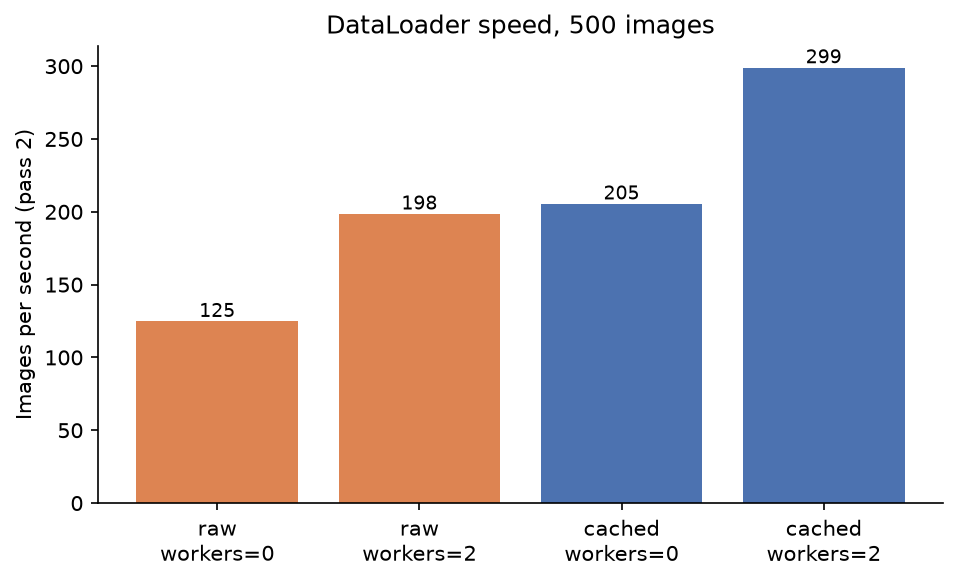

In [9]:
cached_rows = timing[timing['source'] == 'cached']
best = cached_rows.loc[cached_rows['pass2_s'].idxmin()]
BEST_WORKERS = int(best['num_workers'])
print(f'Chosen num_workers = {BEST_WORKERS} ({best.pass2_img_per_s:.0f} images/s on cached data, pass 2)')
raw0 = timing[(timing.source == 'raw') & (timing.num_workers == 0)].pass2_s.iloc[0]
cached0 = timing[(timing.source == 'cached') & (timing.num_workers == 0)].pass2_s.iloc[0]
print(f'Cache speed-up with 0 workers: {raw0 / cached0:.1f}x')
display(ShowImage(filename=str(d.plot_loader_timing(timing, PLOT_DIR))))

## What we found (Week 2 summary)
**CSV index:** v1 = 7,023 rows (5,712 train / 1,311 test), v2 = 7,200 rows (5,600 / 1,600), matching Week 1.

**Crop:** the Otsu crop worked on almost every image. The fallback (full image kept) was used for
10 of 7,023 v1 images (0.14%) and 14 of 7,200 v2 images (0.19%). Most fallbacks are notumor (v1: 7 of 10).
The before/after examples show tight boxes around the head without cutting the skull, and padding keeps the shape.

**Cache:** 7,023 + 7,200 preprocessed 224x224 greyscale PNGs, 181.1 MB (v1) + 185.7 MB (v2), in `outputs/cache/`.

**Dataset check:** one item is a `(3, 224, 224)` float32 tensor; the 3 channels are identical (grey copied 3 times).
The pixel mean after ImageNet normalisation is -1.379, not 0, because most of an MRI is black background
(black becomes about -2.1 after normalisation). This is expected.

**DataLoader speed (500 training images, batch 32, train augmentations):**

| Source | num_workers | Pass 1 (s) | Pass 2 (s) | Pass 2 images/s |
|---|---|---|---|---|
| raw (crop every time) | 0 | 6.92 | 4.01 | 124.7 |
| raw (crop every time) | 2 | 32.88 | 2.52 | 198.5 |
| cached | 0 | 12.12 | 2.43 | 205.4 |
| cached | 2 | 33.12 | 1.67 | 298.9 |

- **Choice: `num_workers=2` with the cache**, the fastest in steady state (299 images/s, pass 2).
- Starting 2 worker processes on Windows costs about 30 s (pass 1), because each worker has to import PyTorch again.
  This is paid **once per training run** with `persistent_workers=True`, so with 25 epochs it is worth it.
- The cache is 1.7x faster than cropping on the fly (0 workers, pass 2).
- Note: pass 1 of "cached, 0 workers" (12.1 s) was slower than its pass 2 because the PNGs were read from disk for the first time.
  These are single measurements on this laptop, so they should be read as rough values.

**Next (Week 3):** duplicate audit (MD5 + pHash) for each version.